In [1]:
# Setup: CPU-only analysis of existing rasters and predictions; no training or dataset changes.
import os, sys, json, hashlib, csv, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage, stats
from sklearn.metrics import roc_auc_score
from IPython.display import display

for candidate in (Path('.'), Path('..'), Path('../..'), Path('../../..')):
    if (candidate / 'src/use_croma.py').is_file():
        os.chdir(candidate)
        break
else:
    raise FileNotFoundError('Open this notebook from inside the repository.')
ROOT = Path.cwd()
EXPERIMENT = Path('experiments/croma_sen1floods11/S1_S2_acquisition_analysis')
DATA = Path('dataset/sen1floods11_hand_labeled_only')
HAND = DATA / 'HandLabeled'
OUT = Path('reports/s1_s2_acquisition_analysis') / datetime.now().strftime('%Y-%m-%d_%H-%M-%S_%f')
OUT.mkdir(parents=True, exist_ok=False)
# Explicit paths make this comparison reproducible; set either to None to discover the latest complete test.
S1_RUN = Path('runs/croma_sen1floods11/UperNet_head_S1/test_croma_large_upernet_pangaea_sar_2026-10-22_16-53-42_953262_75b6c9f3')
S2_RUN = Path('runs/croma_sen1floods11/UperNet_Head_S2/test_croma_large_upernet_pangaea_s2_2026-10-24_19-19-25_195280_3f3c3244')
SEED = 234
S2_BANDS = [1,2,3,4,5,6,7,8,9,10,12,13]
SPLIT_FILES = {'train':'flood_train_data.csv', 'valid':'flood_valid_data.csv',
               'non_bol':'flood_test_data.csv', 'bol':'flood_bolivia_data.csv'}
EXPECTED_COUNTS = {'train':252, 'valid':89, 'non_bol':90, 'bol':15}
COUNTS = ['TP','FP','FN','TN']
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
pd.set_option('display.max_columns', 20)
print('Outputs:', OUT)


Outputs: reports\s1_s2_acquisition_analysis\2026-10-24_19-48-12_783046


In [2]:
# Literature evidence: summaries, not verbatim quotations. URLs are included in exported tables.
DATASET_PAPER = 'https://www.grss-ieee.org/wp-content/uploads/earthvision2020/july_stuff/webpage/papers/Bonafilia_Sen1Floods11_A_Georeferenced_Dataset_to_Train_and_Test_Deep_Learning_CVPRW_2020_paper.pdf'
CROMA_PAPER = 'https://papers.neurips.cc/paper_files/paper/2023/file/11822e84689e631615199db3b75cd0e4-Paper-Conference.pdf'
sources = pd.DataFrame([
    {'topic':'Acquisition timing', 'evidence':'Pairs were selected on the same day or within two days; this is an upper bound, not a fixed lag.', 'source':DATASET_PAPER, 'section':'2.2'},
    {'topic':'Label provenance', 'evidence':'An S2-derived water classification was corrected by analysts with access to S2 false-colour composites AND S1 VH. Labels are not exclusively based on S2.', 'source':DATASET_PAPER, 'section':'2.2 Hand Labeling'},
    {'topic':'Selection effects', 'evidence':'Cloud-heavy chips were excluded and sampling used S2-classified water coverage. This can affect the benchmark population.', 'source':DATASET_PAPER, 'section':'2.2'},
    {'topic':'CROMA pretraining', 'evidence':'SSL4EO paired S1 GRD and S2 L2A images; contrastive alignment and masked reconstruction jointly train radar, optical and joint encoders.', 'source':CROMA_PAPER, 'section':'2 and 3'},
    {'topic':'Architecture', 'evidence':'The optical encoder has twice the transformer depth of the radar encoder. Our selected intermediate layers must also be considered.', 'source':CROMA_PAPER, 'section':'2; src/use_croma.py'},
    {'topic':'Optical product shift', 'evidence':'CROMA pretraining uses S2 L2A; Sen1Floods11 supplies S2 L1C. This is a domain difference, not proof of the observed accuracy gap.', 'source':'https://github.com/cloudtostreet/Sen1Floods11', 'section':'Layer descriptions; CROMA section 3'},
])
sources.to_csv(OUT/'literature_evidence.csv', index=False)
display(sources)
print('These sources establish provenance and plausible mechanisms. They do not identify the cause of our model errors.')


,topic,evidence,source,section
0,Acquisition timing,Pairs were selected on the same day or within ...,https://www.grss-ieee.org/wp-content/uploads/e...,2.2
1,Label provenance,An S2-derived water classification was correct...,https://www.grss-ieee.org/wp-content/uploads/e...,2.2 Hand Labeling
2,Selection effects,Cloud-heavy chips were excluded and sampling u...,https://www.grss-ieee.org/wp-content/uploads/e...,2.2
3,CROMA pretraining,SSL4EO paired S1 GRD and S2 L2A images; contra...,https://papers.neurips.cc/paper_files/paper/20...,2 and 3
4,Architecture,The optical encoder has twice the transformer ...,https://papers.neurips.cc/paper_files/paper/20...,2; src/use_croma.py
5,Optical product shift,CROMA pretraining uses S2 L2A; Sen1Floods11 su...,https://github.com/cloudtostreet/Sen1Floods11,Layer descriptions; CROMA section 3


These sources establish provenance and plausible mechanisms. They do not identify the cause of our model errors.


In [3]:
# Event metadata supplies calendar dates, not per-scene acquisition timestamps.
provenance = json.loads((EXPERIMENT/'references/metadata_provenance.json').read_text())
metadata_path = EXPERIMENT/'references/Sen1Floods11_Metadata.geojson'
assert hashlib.sha256(metadata_path.read_bytes()).hexdigest() == provenance['sha256']
events = pd.DataFrame([f['properties'] for f in json.loads(metadata_path.read_text())['features']])
events = events.rename(columns={'location':'event'})
events['metadata_event_name'] = events.event
# The Cambodia flood event is named Mekong in the raster filenames and split CSVs.
events['event'] = events.event.replace({'Cambodia':'Mekong'})
for col in ['s1_date','s2_date']:
    events[col] = pd.to_datetime(events[col], format='%Y/%m/%d', errors='raise')
events['signed_delta_days'] = (events.s2_date-events.s1_date).dt.days
events['abs_delta_days'] = events.signed_delta_days.abs()
assert events.event.is_unique
rows = []
for split, filename in SPLIT_FILES.items():
    with (DATA/'flood_handlabeled'/filename).open(newline='') as handle:
        pairs = list(csv.reader(handle))
    assert len(pairs)==EXPECTED_COUNTS[split]
    for s1_name, label_name in pairs:
        chip = s1_name.strip().removesuffix('_S1Hand.tif')
        assert label_name.strip()==chip+'_LabelHand.tif'
        stac_path = DATA/'catalog/sen1floods11_hand_labeled_source'/chip/(chip+'.json')
        stac = json.loads(stac_path.read_text()) if stac_path.exists() else {}
        props = stac.get('properties', {})
        rows.append({'chip_id':chip, 'event':chip.rsplit('_',1)[0], 'split':split,
                     'stac_s1_datetime':props.get('datetime'),
                     'stac_has_s2_asset':'S2Hand' in stac.get('assets', {})})
chips = pd.DataFrame(rows)
assert chips.chip_id.is_unique, 'Duplicate or overlapping split membership'
chips = chips.merge(events[['event','s1_date','s2_date','signed_delta_days','abs_delta_days','orbit','VH_thresh']], on='event', how='left', validate='many_to_one')
assert chips.s1_date.notna().all() and chips.s2_date.notna().all()
chips['date_source'] = 'official_event_metadata_calendar_day'
stac_day = pd.to_datetime(chips.stac_s1_datetime, utc=True).dt.tz_localize(None).dt.normalize()
chips['stac_s1_matches_event_date'] = stac_day.eq(chips.s1_date).where(stac_day.notna())
chips.to_csv(OUT/'chip_acquisition_dates.csv', index=False)
used_events = events[events.event.isin(chips.event)].copy()
used_events.to_csv(OUT/'event_acquisition_dates.csv', index=False)
display(used_events[['event','s1_date','s2_date','signed_delta_days','abs_delta_days']].sort_values('signed_delta_days'))
print('Positive delta: S2 later than S1. Negative delta: S2 earlier than S1.')
print('Same calendar day does NOT establish simultaneous acquisition or a zero-hour lag.')
print('STAC date disagreements:', int((chips.stac_s1_matches_event_date==False).sum()))
print('S2-specific STAC assets:', int(chips.stac_has_s2_asset.sum()), 'of',len(chips))
print('Unused metadata events:', sorted(set(events.event)-set(chips.event)))


,event,s1_date,s2_date,signed_delta_days,abs_delta_days
8,Somalia,2018-05-07,2018-05-05,-2,2
10,Sri-Lanka,2017-05-30,2017-05-28,-2,2
5,Nigeria,2018-09-21,2018-09-20,-1,1
4,Mekong,2018-08-05,2018-08-04,-1,1
6,Pakistan,2017-06-28,2017-06-28,0,0
3,India,2016-08-12,2016-08-12,0,0
7,Paraguay,2018-10-31,2018-10-31,0,0
0,Bolivia,2018-02-15,2018-02-15,0,0
11,USA,2019-05-22,2019-05-22,0,0
2,Ghana,2018-09-18,2018-09-19,1,1


Positive delta: S2 later than S1. Negative delta: S2 earlier than S1.
Same calendar day does NOT establish simultaneous acquisition or a zero-hour lag.
STAC date disagreements: 0
S2-specific STAC assets: 0 of 446
Unused metadata events: ['Colombia']


absolute calendar-day gap,0,1,2
split,,,
train,136,77,39
valid,48,27,14
non_bol,48,27,15
bol,15,0,0


independent events per gap,0,1,2
split,,,
train,4,4,2
valid,4,4,2
non_bol,4,4,2
bol,1,0,0


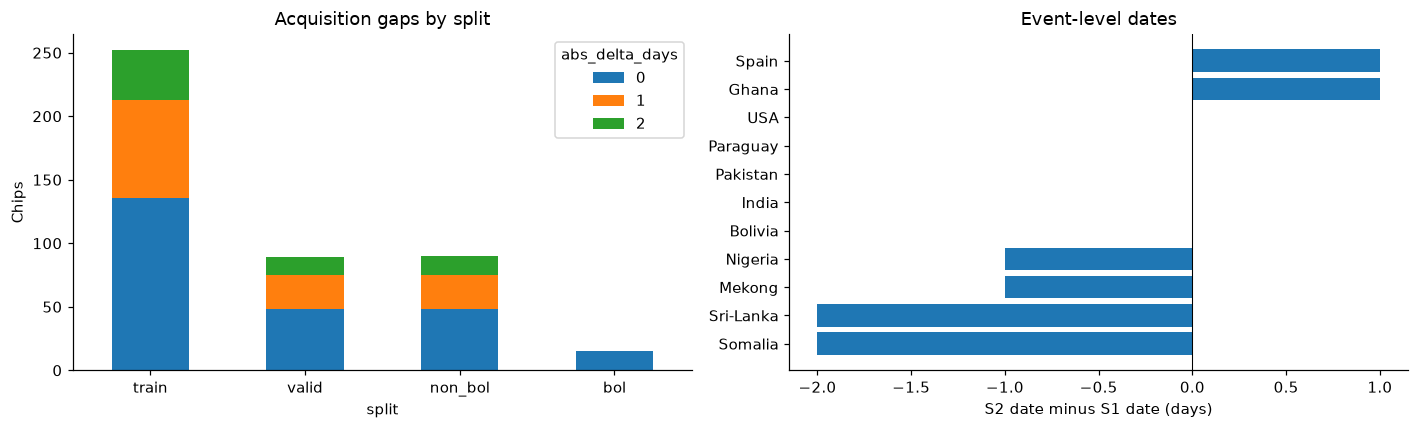

Many chips share one event and one date pair; they are not independent observations of acquisition lag.


In [4]:
# Distribution of acquisition gaps across actual CSV membership, not metadata training-chip counts.
gap_counts = pd.crosstab(chips.split, chips.abs_delta_days).reindex(EXPECTED_COUNTS).fillna(0).astype(int)
event_counts = chips.groupby(['split','abs_delta_days']).event.nunique().unstack(fill_value=0).reindex(EXPECTED_COUNTS)
gap_counts.to_csv(OUT/'gap_counts_by_split.csv')
event_counts.to_csv(OUT/'independent_events_by_split_and_gap.csv')
display(gap_counts.rename_axis(columns='absolute calendar-day gap'))
display(event_counts.rename_axis(columns='independent events per gap'))
fig, axes = plt.subplots(1,2,figsize=(13,4))
gap_counts.plot.bar(stacked=True,ax=axes[0],rot=0)
axes[0].set(ylabel='Chips', title='Acquisition gaps by split')
ordered = used_events.sort_values(['signed_delta_days','event'])
axes[1].barh(ordered.event,ordered.signed_delta_days)
axes[1].axvline(0,color='black',lw=0.7)
axes[1].set(xlabel='S2 date minus S1 date (days)', title='Event-level dates')
fig.tight_layout();fig.savefig(OUT/'acquisition_gaps.png');plt.show()
print('Many chips share one event and one date pair; they are not independent observations of acquisition lag.')


In [5]:
# Select runs by provenance, never by the best test score. Require complete official test predictions.
def complete_run(folder, suffix):
    if not (folder/'run.json').is_file(): return False
    for split in ['non_bol','bol']:
        expected = set(chips.loc[chips.split==split,'chip_id'])
        actual = {p.name.removesuffix(suffix) for p in (folder/split).glob('*'+suffix)}
        if actual!=expected: return False
    return True

def select_run(exp, override, suffix):
    if override is not None:
        folder = Path(override)
        if not complete_run(folder,suffix): raise ValueError(f'Incomplete test predictions: {folder}')
        return folder
    candidates = [p.parent for p in (Path('runs/croma_sen1floods11')/exp).glob('test_*/run.json') if complete_run(p.parent,suffix)]
    if not candidates: raise FileNotFoundError(f'No complete test run: {exp}')
    return max(candidates,key=lambda p:json.loads((p/'run.json').read_text())['started_at'])

RUNS = {'S1':select_run('UperNet_head_S1',S1_RUN,'_S1Hand_prediction.tif'),
        'S2':select_run('UperNet_Head_S2',S2_RUN,'_S2Hand_prediction.tif')}
run_info = {k:json.loads((v/'run.json').read_text()) for k,v in RUNS.items()}
train_info = {k:json.loads((Path(v['checkpoint']).parent/'run.json').read_text()) for k,v in run_info.items()}
settings = ['epochs','eval_interval','batch_size','crop_size','loss','optimizer','learning_rate',
            'weight_decay','scheduler','seed','backbone_frozen','checkpoint_selection','head_config','inference_grid']
protocol = pd.DataFrame([{'setting':k,'S1':str(train_info['S1'].get(k)), 'S2':str(train_info['S2'].get(k)),
                         'matches':train_info['S1'].get(k)==train_info['S2'].get(k)} for k in settings])
protocol.to_csv(OUT/'protocol_comparison.csv',index=False)
display(protocol)
for modality in RUNS:
    print(modality, RUNS[modality], 'checkpoint epoch:',run_info[modality]['checkpoint_epoch'])
print('One seed per modality; matching settings do not control label provenance, sensor physics or pretrained representations.')
print('Training/validation acquisition dates are audited, but spatial prediction comparisons below use saved test predictions only.')


,setting,S1,S2,matches
0,epochs,80,80,True
1,eval_interval,2,2,True
2,batch_size,8,8,True
3,crop_size,120,120,True
4,loss,unweighted_cross_entropy,unweighted_cross_entropy,True
5,optimizer,AdamW,AdamW,True
6,learning_rate,0.0001,0.0001,True
7,weight_decay,0.05,0.05,True
8,scheduler,"{'name': 'MultiStepLR', 'milestones': [1488, 2...","{'name': 'MultiStepLR', 'milestones': [1488, 2...",True
9,seed,234,234,True


S1 runs\croma_sen1floods11\UperNet_head\test_croma_large_upernet_pangaea_sar_2026-10-22_16-53-42_953262_75b6c9f3 checkpoint epoch: 68
S2 runs\croma_sen1floods11\UperNet_Head_S2\test_croma_large_upernet_pangaea_s2_2026-10-24_19-19-25_195280_3f3c3244 checkpoint epoch: 56
One seed per modality; matching settings do not control label provenance, sensor physics or pretrained representations.
Training/validation acquisition dates are audited, but spatial prediction comparisons below use saved test predictions only.


In [6]:
# Raster and metric helpers. All comparisons use identical masks for both models.
def read_grid(path, reference=None, bands=1, masked=False):
    with rasterio.open(path) as src:
        grid = (src.shape, src.crs, src.transform)
        if reference is not None:
            assert grid[0]==reference[0] and grid[1]==reference[1] and grid[2].almost_equals(reference[2],precision=1e-10), path
        data = src.read(bands, masked=masked, out_dtype='float32' if masked else None)
    return (data.filled(np.nan) if masked else data), grid

def paths(chip):
    return {k:HAND/k/(chip+'_'+k+'.tif') for k in ['LabelHand','S1Hand','S2Hand','JRCWaterHand','S1OtsuLabelHand']}

def counts_for(pred, label, valid):
    return dict(zip(COUNTS,[int(np.count_nonzero(valid & (pred==p) & (label==t))) for p,t in [(1,1),(1,0),(0,1),(0,0)]]))

def ratio(a,b): return a/b if b else np.nan

def metrics(c):
    tp,fp,fn,tn=[int(c[k]) for k in COUNTS]
    wi=ratio(tp,tp+fp+fn);li=ratio(tn,tn+fp+fn)
    return {'water_iou':wi, 'miou':(wi+li)/2, 'accuracy':ratio(tp+tn,tp+fp+fn+tn),
            'precision':ratio(tp,tp+fp), 'recall':ratio(tp,tp+fn), 'f1':ratio(2*tp,2*tp+fp+fn),
            'omission':ratio(fn,tp+fn), 'commission':ratio(fp,tp+fp), 'valid_pixels':tp+fp+fn+tn}

def pool(frame,group_cols):
    output=[]
    for key,g in frame.groupby(group_cols,dropna=False,observed=True):
        if not isinstance(key,tuple):key=(key,)
        c={k:int(g[k].sum()) for k in COUNTS}
        output.append({**dict(zip(group_cols,key)), 'chips':g.chip_id.nunique(), 'events':g.event.nunique(),
                       **c,**metrics(c),'mean_chip_water_iou':g.water_iou.mean(),
                       'defined_chip_water_ious':int(g.water_iou.notna().sum())})
    return pd.DataFrame(output)


In [7]:
# Audit all 446 paired inputs and labels; sample raw signals independently of CROMA.
# These AUCs describe agreement with existing labels, not correctness against an independent truth.
rng=np.random.default_rng(SEED)
audit_rows=[];signal_rows=[]
for i,row in enumerate(chips.itertuples(index=False)):
    ps=paths(row.chip_id)
    y,grid=read_grid(ps['LabelHand'])
    s1,_=read_grid(ps['S1Hand'],grid,[1,2],masked=True)
    s2,_=read_grid(ps['S2Hand'],grid,S2_BANDS,masked=True)
    assert np.isin(y,[-1,0,1,255]).all()
    valid=np.isin(y,[0,1]); water=valid & (y==1)
    v1=np.isfinite(s1).all(axis=0);v2=np.isfinite(s2).all(axis=0)
    common=valid & v1 & v2
    components,n=ndimage.label(water)
    sizes=np.bincount(components.ravel())
    small=water & (sizes[components]<=64)
    audit_rows.append({'chip_id':row.chip_id,'labeled_pixels':int(valid.sum()),'water_pixels':int(water.sum()),
        'water_fraction':ratio(water.sum(),valid.sum()),'ignored_fraction':1-valid.mean(),
        's1_usable_fraction':float(v1.mean()),'s2_usable_fraction':float(v2.mean()),
        'both_usable_labeled_pixels':int(common.sum()),'water_components':n,
        'small_component_water_fraction':ratio(small.sum(),water.sum())})
    w=np.flatnonzero(common & (y==1));land=np.flatnonzero(common & (y==0))
    # Equal sampling per class per chip makes this a signal-separability diagnostic, not a pooled benchmark score.
    if len(w) and len(land):
        selected=np.r_[rng.choice(w,min(256,len(w)),replace=False),rng.choice(land,min(256,len(land)),replace=False)]
        target=y.ravel()[selected]
        green=s2[2].ravel()[selected];swir=s2[10].ravel()[selected]
        mndwi=(green-swir)/(green+swir+1e-8)
        for name,score in [('S1_negative_VH',-s1[1].ravel()[selected]),('S2_negative_NIR',-s2[7].ravel()[selected]),('S2_MNDWI',mndwi)]:
            signal_rows.append({'chip_id':row.chip_id,'signal':name,'auc':roc_auc_score(target,score),'sampled_pixels':len(selected)})
    if (i+1)%100==0:print('Audited',i+1,'/',len(chips))
audit=chips.merge(pd.DataFrame(audit_rows),on='chip_id',validate='one_to_one')
audit['usable_both_images']=(audit.s1_usable_fraction>0)&(audit.s2_usable_fraction>0)
audit.to_csv(OUT/'input_and_label_audit.csv',index=False)
signals=pd.DataFrame(signal_rows).merge(chips[['chip_id','split','event','abs_delta_days']],on='chip_id',validate='many_to_one')
signals.to_csv(OUT/'raw_signal_separability.csv',index=False)
display(audit.groupby('split').agg(chips=('chip_id','size'),mean_water_fraction=('water_fraction','mean'),
    fully_ignored=('labeled_pixels',lambda x:int((x==0).sum())),usable_both_images=('usable_both_images','sum')))
display(audit.loc[~audit.usable_both_images,['chip_id','split','s1_usable_fraction','s2_usable_fraction']])


Audited 100 / 446


Audited 200 / 446


Audited 300 / 446


Audited 400 / 446


,chips,mean_water_fraction,fully_ignored,usable_both_images
split,,,,
bol,15,0.169921,0,15
non_bol,90,0.135141,1,89
train,252,0.093784,1,252
valid,89,0.114226,3,89


,chip_id,split,s1_usable_fraction,s2_usable_fraction
391,Paraguay_34417,non_bol,0.0,0.0


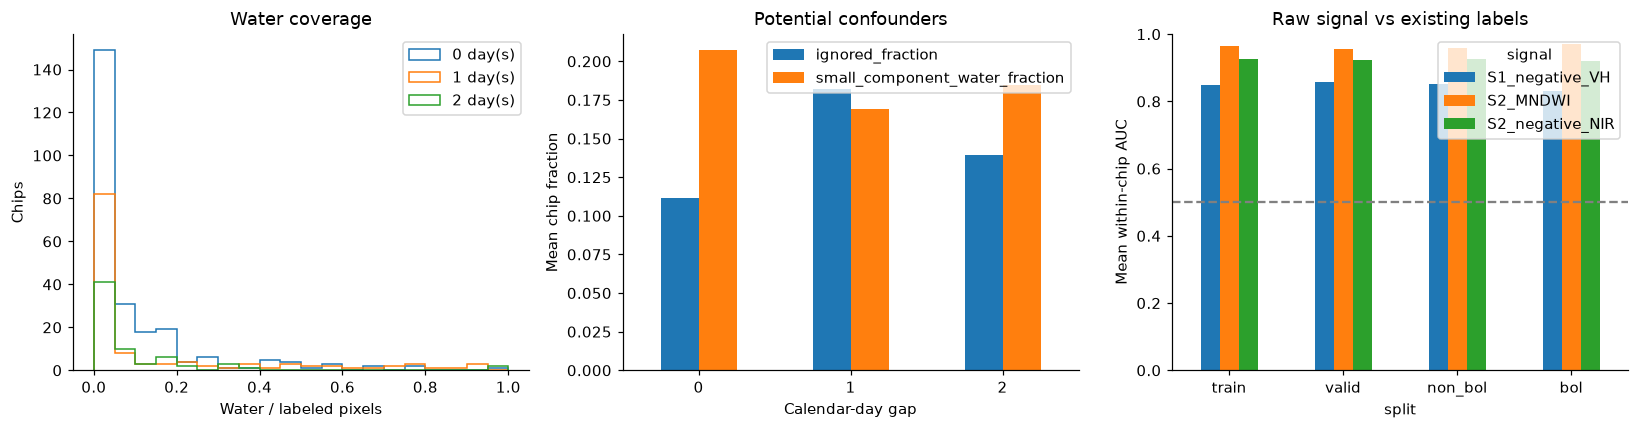

S2 spectral agreement can reflect physical separability AND label construction. It does not isolate pretraining.
Small components use a descriptive 64-pixel cutoff; no test-driven threshold tuning is performed.


In [8]:
# Check whether label coverage and small water regions differ across lag groups.
fig,axes=plt.subplots(1,3,figsize=(15,4))
for gap,g in audit.groupby('abs_delta_days'):
    axes[0].hist(g.water_fraction.dropna(),bins=np.linspace(0,1,21),histtype='step',label=f'{gap} day(s)')
axes[0].set(xlabel='Water / labeled pixels',ylabel='Chips',title='Water coverage');axes[0].legend()
audit.groupby('abs_delta_days')[['ignored_fraction','small_component_water_fraction']].mean().plot.bar(ax=axes[1],rot=0)
axes[1].set(xlabel='Calendar-day gap',ylabel='Mean chip fraction',title='Potential confounders')
signals.groupby(['split','signal']).auc.mean().unstack().reindex(EXPECTED_COUNTS).plot.bar(ax=axes[2],rot=0)
axes[2].axhline(.5,color='gray',ls='--');axes[2].set(ylabel='Mean within-chip AUC',ylim=(0,1),title='Raw signal vs existing labels')
fig.tight_layout();fig.savefig(OUT/'input_label_and_signal_diagnostics.png');plt.show()
print('S2 spectral agreement can reflect physical separability AND label construction. It does not isolate pretraining.')
print('Small components use a descriptive 64-pixel cutoff; no test-driven threshold tuning is performed.')


In [9]:
# Recompute paired prediction metrics on the same test chips and masks.
# JRC overlap is a historical permanent-water proxy, not contemporaneous ground truth for flood change.
metric_rows=[];disagreement_rows=[];water_rows=[]
for row in audit[audit.split.isin(['non_bol','bol'])].itertuples(index=False):
    ps=paths(row.chip_id);y,grid=read_grid(ps['LabelHand'])
    s1,_=read_grid(ps['S1Hand'],grid,[1,2],masked=True)
    s2,_=read_grid(ps['S2Hand'],grid,S2_BANDS,masked=True)
    valid=np.isin(y,[0,1]); common=valid & np.isfinite(s1).all(axis=0) & np.isfinite(s2).all(axis=0)
    water=valid & (y==1)
    safe=ndimage.binary_erosion(valid,iterations=2)
    boundary=(ndimage.binary_dilation(water,iterations=2)^ndimage.binary_erosion(water,iterations=2)) & safe
    jrc,_=read_grid(ps['JRCWaterHand'],grid);assert np.isin(jrc,[0,1]).all()
    components,_=ndimage.label(water);sizes=np.bincount(components.ravel())
    masks={'original':valid,'both_inputs_valid':common,
           'boundary_2px':common & boundary,'interior':common & safe & ~boundary}
    predictions={}
    info={'chip_id':row.chip_id,'split':row.split,'event':row.event,'abs_delta_days':row.abs_delta_days,
          'signed_delta_days':row.signed_delta_days,'water_fraction':row.water_fraction,
          'usable_both_images':row.usable_both_images}
    for modality in ['S1','S2']:
        pred,_=read_grid(RUNS[modality]/row.split/(row.chip_id+'_'+modality+'Hand_prediction.tif'),grid)
        assert np.isin(pred,[0,1]).all();predictions[modality]=pred
        for cohort,mask in masks.items():
            c=counts_for(pred,y,mask)
            metric_rows.append({**info,'modality':modality,'cohort':cohort,**c,**metrics(c)})
        for group,positive in {'JRC_overlap_water':water & (jrc==1),'non_JRC_water':water & (jrc==0),
                               'small_water_components':water & (sizes[components]<=64),
                               'larger_water_components':water & (sizes[components]>64)}.items():
            positive=positive & common
            water_rows.append({**info,'modality':modality,'water_group':group,
                               'detected':int(((pred==1)&positive).sum()),'water_pixels':int(positive.sum())})
    correct1=predictions['S1']==y;correct2=predictions['S2']==y
    disagreement_rows.append({**info,'common_valid_pixels':int(common.sum()),
        's1_wrong_s2_right':int((common & ~correct1 & correct2).sum()),
        's1_right_s2_wrong':int((common & correct1 & ~correct2).sum()),
        'both_wrong':int((common & ~correct1 & ~correct2).sum()),
        's1_water_s2_land':int((common & (predictions['S1']==1)&(predictions['S2']==0)).sum()),
        's1_land_s2_water':int((common & (predictions['S1']==0)&(predictions['S2']==1)).sum())})
results=pd.DataFrame(metric_rows);disagreements=pd.DataFrame(disagreement_rows);water_results=pd.DataFrame(water_rows)
results.to_csv(OUT/'paired_per_chip_metrics.csv',index=False)
disagreements.to_csv(OUT/'paired_disagreements.csv',index=False)
water_results.to_csv(OUT/'water_type_detection_counts.csv',index=False)
summary=pool(results,['split','cohort','modality'])
summary.to_csv(OUT/'paired_pooled_metrics.csv',index=False)
# Verify the original cohort exactly reproduces saved confusion counts.
for modality,folder in RUNS.items():
    saved=pd.read_csv(folder/'metrics_summary.csv').set_index('split')
    for split in ['non_bol','bol']:
        actual=summary[(summary.split==split)&(summary.cohort=='original')&(summary.modality==modality)].iloc[0]
        assert all(int(actual[k])==int(saved.loc[split,k]) for k in COUNTS), (modality,split)
        assert np.isclose(actual.miou,saved.loc[split,'miou'])
display(summary[summary.cohort.isin(['original','both_inputs_valid'])][['split','cohort','modality','chips','water_iou','miou','precision','recall','mean_chip_water_iou']])
print('PASS: recomputed original test metrics match saved confusion counts and mIoU.')


,split,cohort,modality,chips,water_iou,miou,precision,recall,mean_chip_water_iou
0,bol,both_inputs_valid,S1,15,0.548206,0.730643,0.871742,0.596302,0.377140
1,bol,both_inputs_valid,S2,15,0.748013,0.850163,0.955467,0.775034,0.526509
6,bol,original,S1,15,0.545061,0.729087,0.867737,0.594448,0.367111
7,bol,original,S2,15,0.745694,0.848998,0.953863,0.773596,0.538358
8,non_bol,both_inputs_valid,S1,90,0.661320,0.805020,0.862269,0.739428,0.386479
9,non_bol,both_inputs_valid,S2,90,0.839698,0.907984,0.928021,0.898196,0.614611
14,non_bol,original,S1,90,0.649370,0.797783,0.862284,0.724510,0.382066
15,non_bol,original,S2,90,0.824029,0.898804,0.927963,0.880344,0.604587


PASS: recomputed original test metrics match saved confusion counts and mIoU.


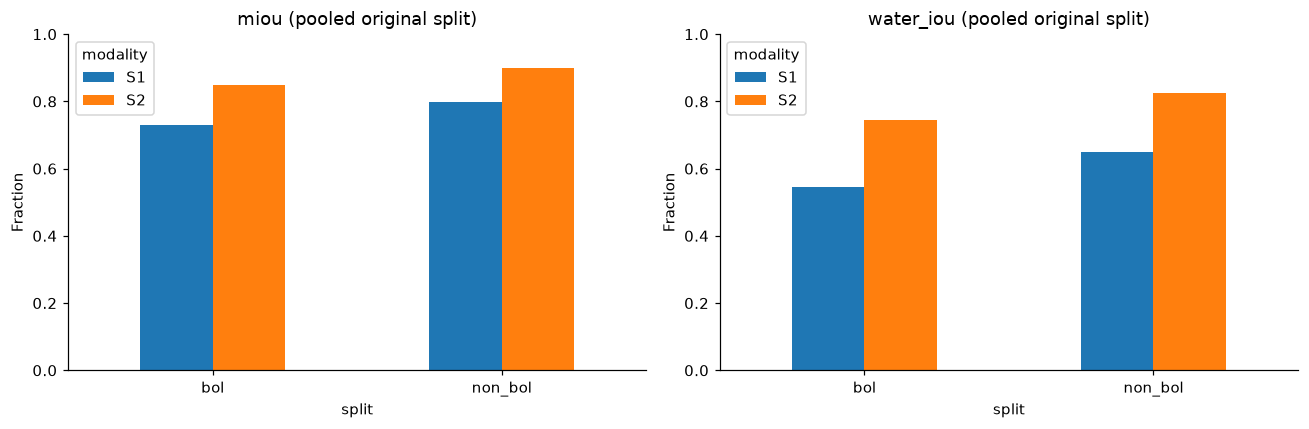

,split,event,abs_delta_days,signed_delta_days,water_iou_S1,water_iou_S2,water_iou_gap_pp,miou_gap_pp
0,bol,Bolivia,0,0,0.548206,0.748013,19.980701,11.952017
1,non_bol,Ghana,1,1,0.514784,0.495072,-1.971217,-1.095492
2,non_bol,India,0,0,0.665672,0.892650,22.697835,14.470800
3,non_bol,Mekong,1,-1,0.854294,0.927844,7.354966,4.393859
4,non_bol,Nigeria,1,-1,0.897460,0.937111,3.965071,2.421739
5,non_bol,Pakistan,0,0,0.143487,0.795145,65.165825,38.656797
6,non_bol,Paraguay,0,0,0.645760,0.729037,8.327662,4.480327
7,non_bol,Somalia,2,-2,0.354520,0.808202,45.368132,24.403269
8,non_bol,Spain,1,1,0.719723,0.839774,12.005140,8.184367
9,non_bol,Sri-Lanka,2,-2,0.859487,0.930830,7.134270,4.480586


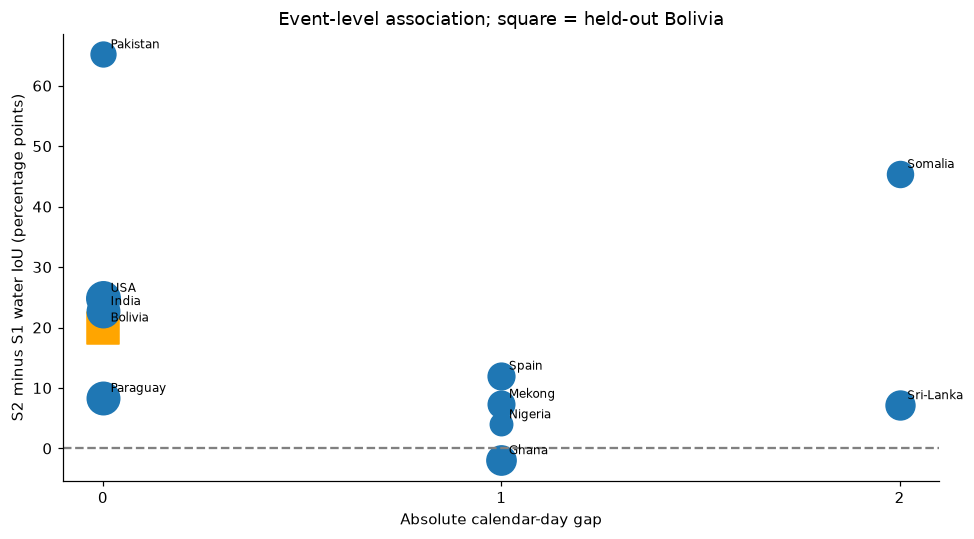

In [10]:
# Compare pooled metrics, then separate event-level gaps from pixel-weighted totals.
fig,axes=plt.subplots(1,2,figsize=(12,4))
original=summary[summary.cohort=='original']
for ax,metric in zip(axes,['miou','water_iou']):
    original.pivot(index='split',columns='modality',values=metric).plot.bar(ax=ax,rot=0,ylim=(0,1))
    ax.set(title=metric+' (pooled original split)',ylabel='Fraction')
fig.tight_layout();fig.savefig(OUT/'s1_s2_test_comparison.png');plt.show()
common_results=results[results.cohort=='both_inputs_valid']
by_event=pool(common_results,['split','event','abs_delta_days','signed_delta_days','modality'])
by_event.to_csv(OUT/'paired_event_metrics.csv',index=False)
event_comparison=by_event.pivot(index=['split','event','abs_delta_days','signed_delta_days'],columns='modality',values=['water_iou','miou','valid_pixels'])
event_comparison.columns=['_'.join(c) for c in event_comparison.columns]
event_comparison=event_comparison.reset_index()
event_comparison['water_iou_gap_pp']=100*(event_comparison.water_iou_S2-event_comparison.water_iou_S1)
event_comparison['miou_gap_pp']=100*(event_comparison.miou_S2-event_comparison.miou_S1)
event_comparison.to_csv(OUT/'s2_minus_s1_by_event.csv',index=False)
display(event_comparison[['split','event','abs_delta_days','signed_delta_days','water_iou_S1','water_iou_S2','water_iou_gap_pp','miou_gap_pp']])
fig,ax=plt.subplots(figsize=(9,5))
for row in event_comparison.itertuples(index=False):
    ax.scatter(row.abs_delta_days,row.water_iou_gap_pp,s=max(30,np.sqrt(row.valid_pixels_S1)/4),
               marker='s' if row.split=='bol' else 'o',color='orange' if row.split=='bol' else 'tab:blue')
    ax.annotate(row.event,(row.abs_delta_days,row.water_iou_gap_pp),xytext=(5,4),textcoords='offset points',fontsize=8)
ax.axhline(0,color='gray',ls='--');ax.set(xticks=[0,1,2],xlabel='Absolute calendar-day gap',ylabel='S2 minus S1 water IoU (percentage points)',title='Event-level association; square = held-out Bolivia')
fig.tight_layout();fig.savefig(OUT/'event_gap_association.png');plt.show()


In [11]:
# Timing hypothesis: descriptive event-level uncertainty, not chip-level pseudo-replication.
# Bolivia is kept separate because it is a held-out event and a different evaluation domain.
nonbol_events=event_comparison[event_comparison.split=='non_bol'].dropna(subset=['water_iou_gap_pp'])
rng=np.random.default_rng(SEED)
bootstrap_rows=[]
for gap,g in nonbol_events.groupby('abs_delta_days'):
    values=g.water_iou_gap_pp.to_numpy()
    samples=rng.choice(values,size=(4000,len(values)),replace=True).mean(axis=1)
    bootstrap_rows.append({'abs_delta_days':gap,'events':len(values),'mean_event_water_iou_gap_pp':values.mean(),
        'bootstrap_lower_95':np.quantile(samples,.025) if len(values)>1 else np.nan,
        'bootstrap_upper_95':np.quantile(samples,.975) if len(values)>1 else np.nan})
bootstrap=pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(OUT/'event_bootstrap_by_gap.csv',index=False)
display(bootstrap)
if nonbol_events.abs_delta_days.nunique()>1:
    x=nonbol_events.abs_delta_days.to_numpy();y=nonbol_events.water_iou_gap_pp.to_numpy()
    rho=float(stats.spearmanr(x,y).statistic)
    perm=np.array([stats.spearmanr(x,rng.permutation(y)).statistic for _ in range(4000)])
    permutation_p=(1+np.count_nonzero(np.abs(perm)>=abs(rho)))/(1+len(perm))
    print(f'Exploratory event Spearman rho={rho:.3f}; permutation p={permutation_p:.3f}; n={len(x)} events.')
else:
    rho=permutation_p=np.nan
lag_summary=pool(common_results,['split','abs_delta_days','modality'])
lag_summary.to_csv(OUT/'pooled_metrics_by_gap.csv',index=False)
display(lag_summary[['split','abs_delta_days','modality','events','chips','water_iou','miou']])
print('Each event has one lag, so lag and event are confounded. Event fixed effects cannot identify a separate lag effect here.')
print('Bootstrap intervals describe variation among these few events; they omit seed uncertainty and acquisition-time uncertainty.')
print('No S1-time independent labels or water-level time series are available here, so sensor disagreement cannot establish actual flood expansion/recession.')


,abs_delta_days,events,mean_event_water_iou_gap_pp,bootstrap_lower_95,bootstrap_upper_95
0,0,4,30.269462,12.467378,54.548828
1,1,4,5.338490,0.360329,9.995123
2,2,2,26.251201,7.134270,45.368132


Exploratory event Spearman rho=-0.376; permutation p=0.291; n=10 events.


,split,abs_delta_days,modality,events,chips,water_iou,miou
0,bol,0,S1,1,15,0.548206,0.730643
1,bol,0,S2,1,15,0.748013,0.850163
2,non_bol,0,S1,4,48,0.569440,0.757068
3,non_bol,0,S2,4,48,0.839598,0.909612
4,non_bol,1,S1,4,27,0.737289,0.844125
5,non_bol,1,S2,4,27,0.803914,0.884406
6,non_bol,2,S1,2,15,0.762074,0.860582
7,non_bol,2,S2,2,15,0.906593,0.945478


Each event has one lag, so lag and event are confounded. Event fixed effects cannot identify a separate lag effect here.
Bootstrap intervals describe variation among these few events; they omit seed uncertainty and acquisition-time uncertainty.
No S1-time independent labels or water-level time series are available here, so sensor disagreement cannot establish actual flood expansion/recession.


,split,water_group,modality,detected,water_pixels,recall
0,bol,JRC_overlap_water,S1,28794,29951,0.961370
1,bol,JRC_overlap_water,S2,27067,29951,0.903709
2,bol,larger_water_components,S1,264653,439690,0.601908
3,bol,larger_water_components,S2,345144,439690,0.784971
4,bol,non_JRC_water,S1,238890,418956,0.570203
5,bol,non_JRC_water,S2,320851,418956,0.765835
6,bol,small_water_components,S1,3031,9217,0.328849
7,bol,small_water_components,S2,2774,9217,0.300966
8,non_bol,JRC_overlap_water,S1,891518,899332,0.991311
9,non_bol,JRC_overlap_water,S2,879284,899332,0.977708


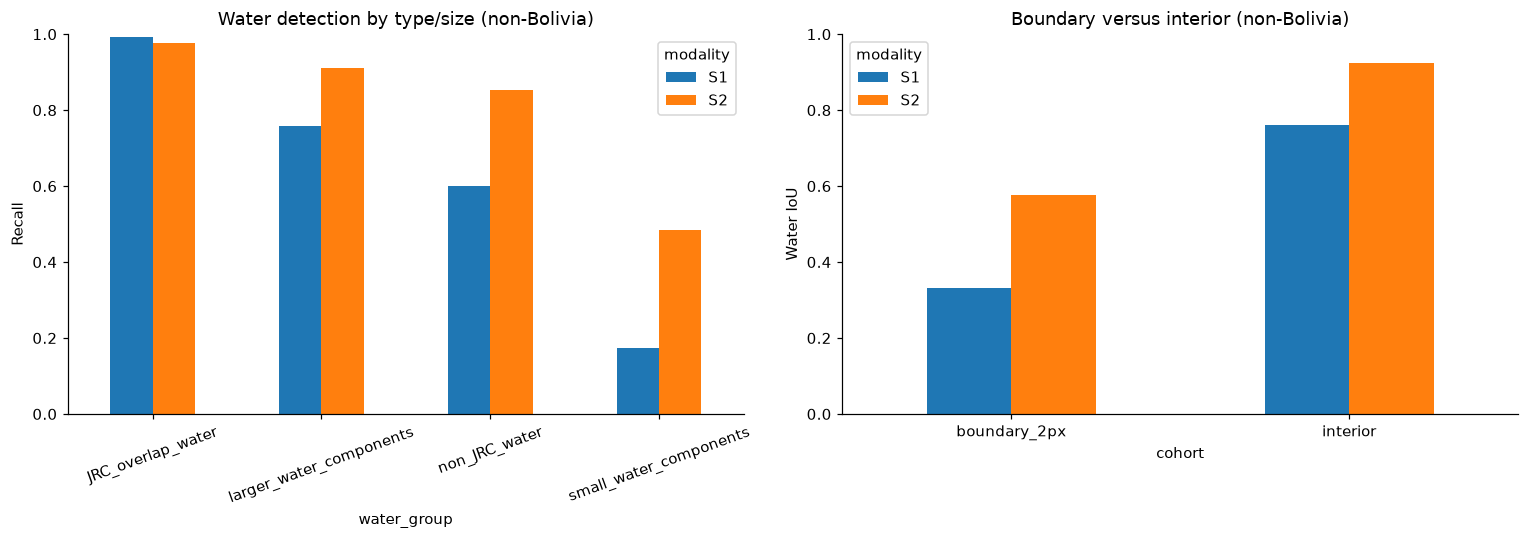

Non-JRC water is not proof of newly flooded water; JRC is historical and can miss water.
Boundary concentration is compatible with timing, registration, annotation ambiguity, or model resolution; it cannot distinguish them alone.


In [12]:
# Boundary/size/permanent-water diagnostics help distinguish possible mechanisms.
water_summary=water_results.groupby(['split','water_group','modality'])[['detected','water_pixels']].sum().reset_index()
water_summary['recall']=water_summary.detected/water_summary.water_pixels.replace(0,np.nan)
water_summary.to_csv(OUT/'water_type_recall.csv',index=False)
display(water_summary)
fig,axes=plt.subplots(1,2,figsize=(14,5))
water_summary[water_summary.split=='non_bol'].pivot(index='water_group',columns='modality',values='recall').plot.bar(ax=axes[0],ylim=(0,1),rot=20)
axes[0].set(title='Water detection by type/size (non-Bolivia)',ylabel='Recall')
summary[(summary.split=='non_bol')&summary.cohort.isin(['boundary_2px','interior'])].pivot(index='cohort',columns='modality',values='water_iou').plot.bar(ax=axes[1],ylim=(0,1),rot=0)
axes[1].set(title='Boundary versus interior (non-Bolivia)',ylabel='Water IoU')
fig.tight_layout();fig.savefig(OUT/'boundary_and_water_type_errors.png');plt.show()
print('Non-JRC water is not proof of newly flooded water; JRC is historical and can miss water.')
print('Boundary concentration is compatible with timing, registration, annotation ambiguity, or model resolution; it cannot distinguish them alone.')


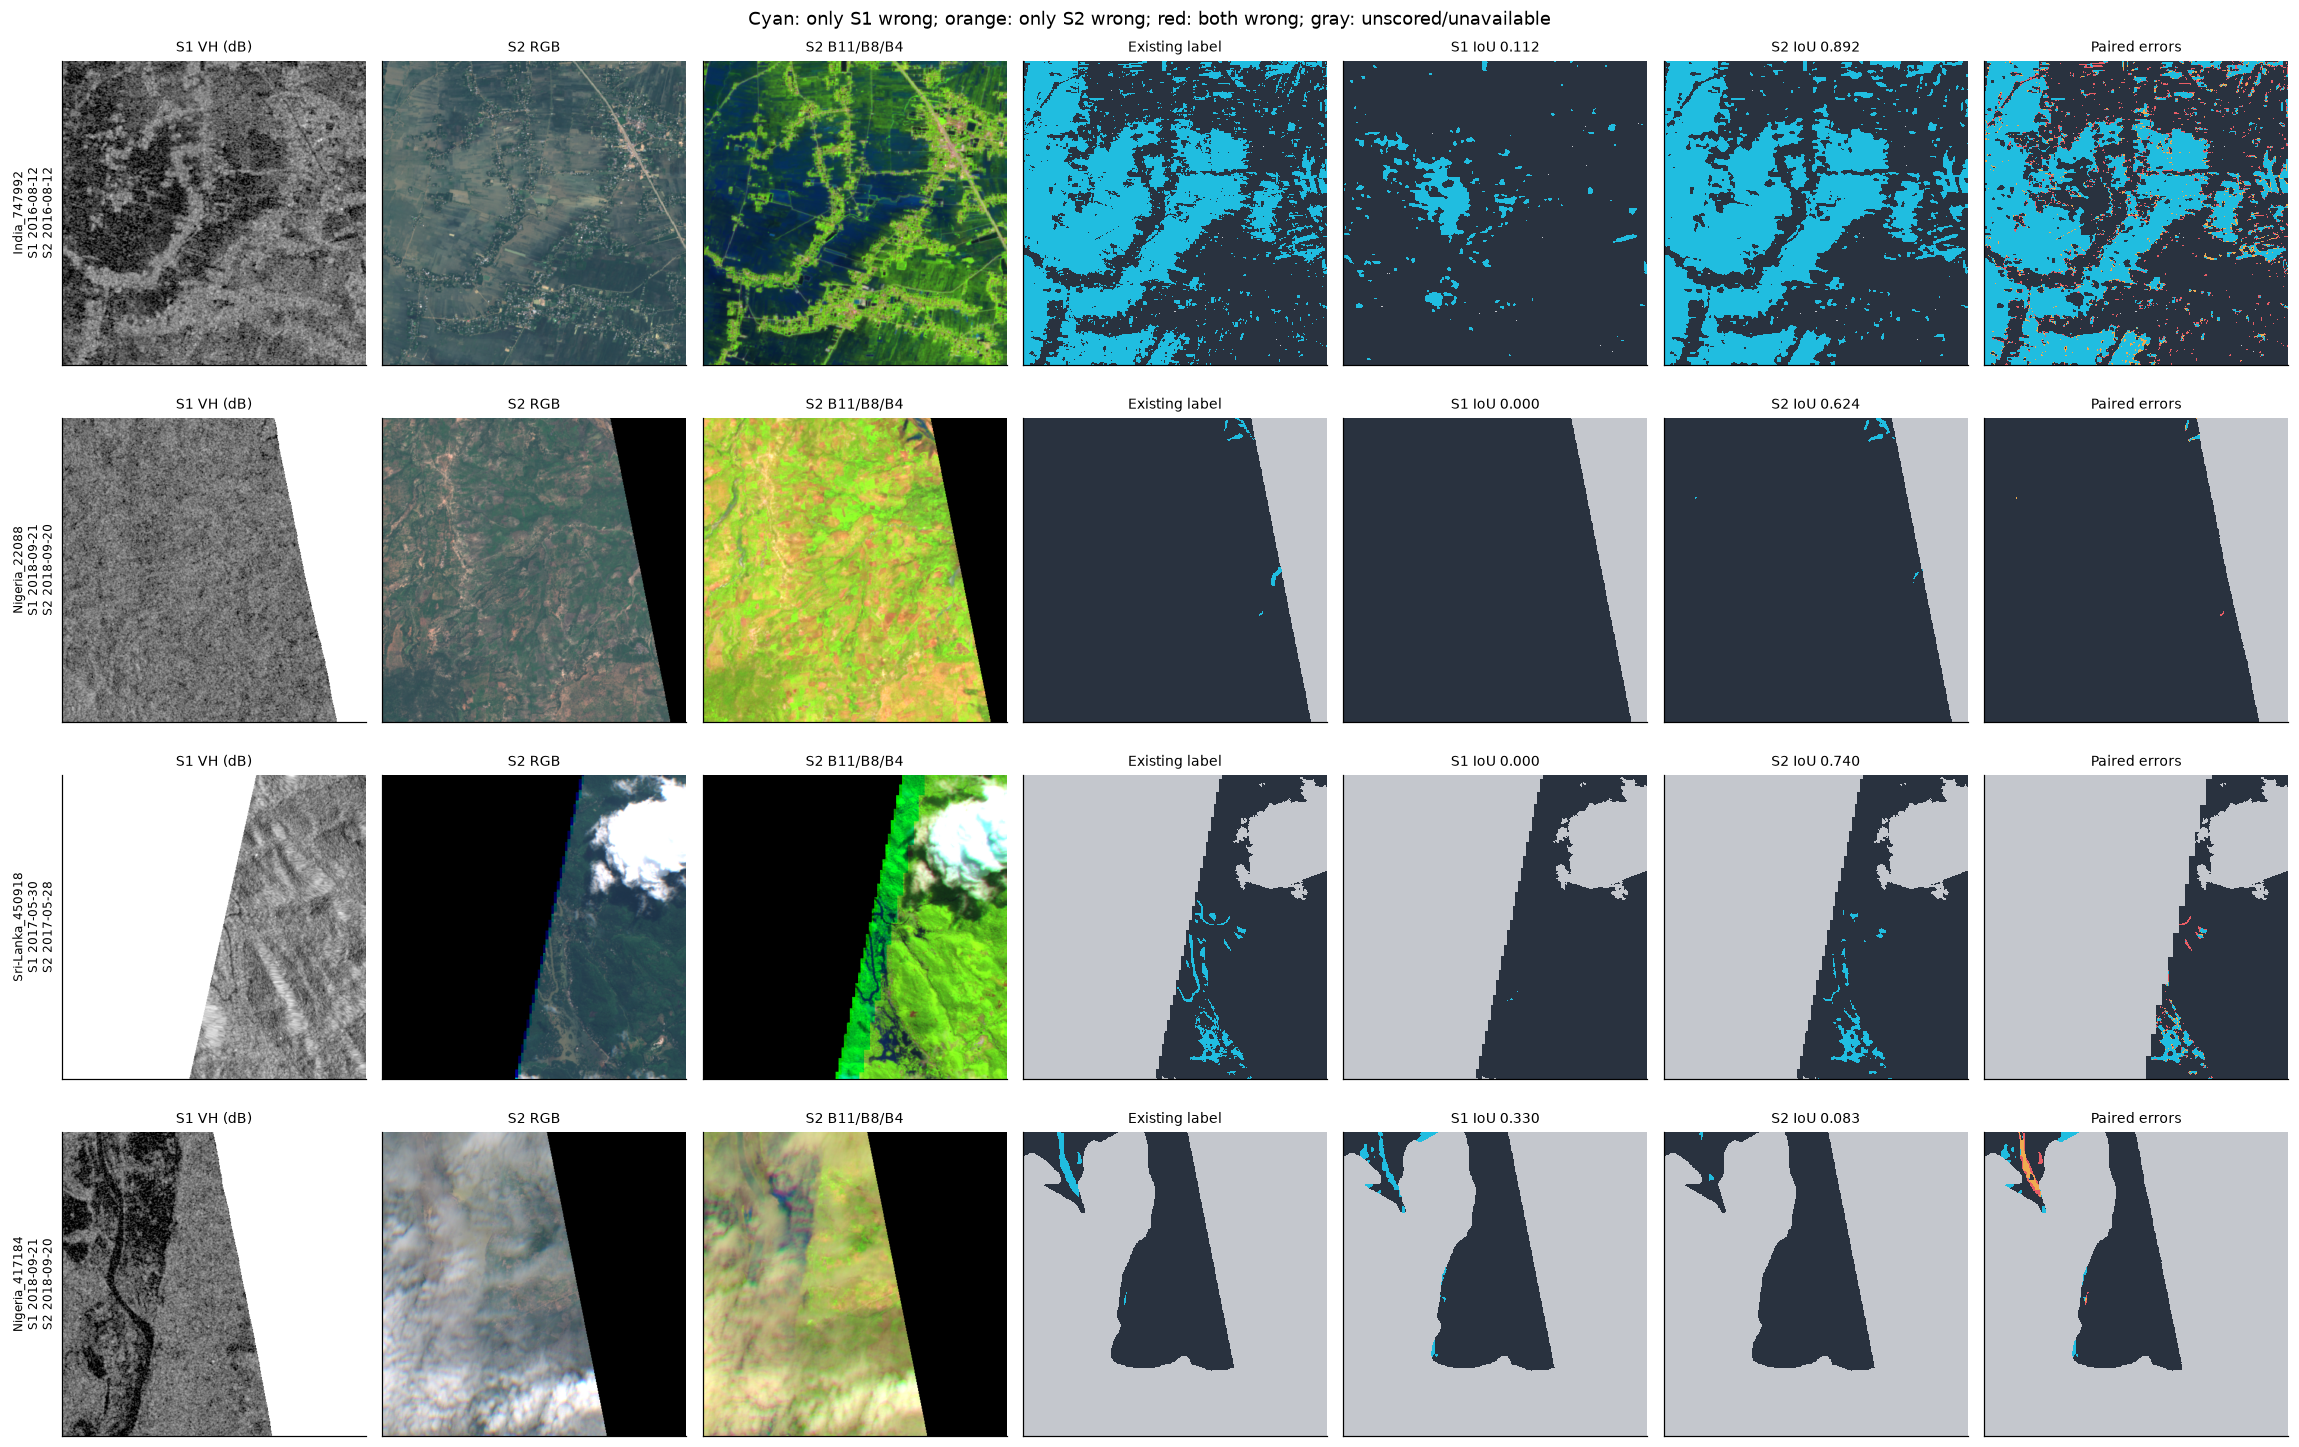

In [13]:
# Visual cases: deliberately selected diagnostics, not a representative sample or evidence of true change.
paired=common_results.pivot(index='chip_id',columns='modality',values='water_iou')
paired['gap']=paired.S2-paired.S1
paired=paired.reset_index().merge(audit,on='chip_id',validate='one_to_one')
choices=[]
for gap in sorted(paired.abs_delta_days.unique()):
    candidates=paired[(paired.abs_delta_days==gap)&(paired.labeled_pixels>0)&paired.usable_both_images].dropna(subset=['gap'])
    if len(candidates):choices.append(candidates.sort_values('gap',ascending=False).iloc[0])
reverse=paired[(paired.labeled_pixels>0)&paired.usable_both_images].dropna(subset=['gap']).sort_values('gap')
if len(reverse) and reverse.iloc[0].chip_id not in [r.chip_id for r in choices]:choices.append(reverse.iloc[0])
case_table=pd.DataFrame(choices)
case_table.to_csv(OUT/'visual_case_selection.csv',index=False)
mask_cmap=ListedColormap(['#29323f','#20bde0','#c4c7cd'])
error_cmap=ListedColormap(['#29323f','#20bde0','#f0ab50','#e85d65','#c4c7cd'])
fig,axes=plt.subplots(len(choices),7,figsize=(21,3.4*len(choices)),squeeze=False)
for idx,row in enumerate(choices):
    ps=paths(row.chip_id);y,grid=read_grid(ps['LabelHand'])
    sar,_=read_grid(ps['S1Hand'],grid,[1,2],masked=True)
    optical,_=read_grid(ps['S2Hand'],grid,[4,3,2,12,8],masked=True)
    all_optical,_=read_grid(ps['S2Hand'],grid,S2_BANDS,masked=True)
    valid=np.isin(y,[0,1]);common=valid & np.isfinite(sar).all(axis=0)&np.isfinite(all_optical).all(axis=0)
    preds={m:read_grid(RUNS[m]/row.split/(row.chip_id+'_'+m+'Hand_prediction.tif'),grid)[0] for m in ['S1','S2']}
    rgb=np.moveaxis(np.clip(np.nan_to_num(optical[:3])/3000,0,1),0,-1)
    # False colour uses B11/B8/B4, with independent display scaling only.
    false=np.moveaxis(np.clip(np.nan_to_num(optical[[3,4,0]])/4000,0,1),0,-1)
    errors=np.zeros(y.shape,dtype=np.uint8)
    c1=preds['S1']==y;c2=preds['S2']==y
    errors[~c1 & c2]=1;errors[c1 & ~c2]=2;errors[~c1 & ~c2]=3;errors[~common]=4
    axes[idx,0].imshow(sar[1],cmap='gray',vmin=-30,vmax=0)
    axes[idx,1].imshow(rgb);axes[idx,2].imshow(false)
    for col,array in [(3,y),(4,preds['S1']),(5,preds['S2'])]:
        axes[idx,col].imshow(np.where(valid,array,2),cmap=mask_cmap,vmin=0,vmax=2,interpolation='nearest')
    axes[idx,6].imshow(errors,cmap=error_cmap,vmin=0,vmax=4,interpolation='nearest')
    titles=['S1 VH (dB)','S2 RGB','S2 B11/B8/B4','Existing label',f'S1 IoU {row.S1:.3f}',f'S2 IoU {row.S2:.3f}','Paired errors']
    for ax,title in zip(axes[idx],titles):ax.set_title(title,fontsize=9);ax.set_xticks([]);ax.set_yticks([])
    axes[idx,0].set_ylabel(f'{row.chip_id}\nS1 {row.s1_date:%Y-%m-%d}\nS2 {row.s2_date:%Y-%m-%d}',fontsize=8)
fig.suptitle('Cyan: only S1 wrong; orange: only S2 wrong; red: both wrong; gray: unscored/unavailable',fontsize=12)
fig.tight_layout();fig.savefig(OUT/'paired_visual_cases.png',dpi=130);plt.show()


In [14]:
# Pretraining hypothesis: inspect the actual downstream setup without loading or retraining CROMA.
architecture=[]
for modality in ['S1','S2']:
    depth=12 if modality=='S1' else 24  # CROMA-large, verified in src/use_croma.py.
    selected=run_info[modality]['head_config']['out_indices']
    architecture.append({'modality':modality,'input_channels':2 if modality=='S1' else 12,
        'pretrained_encoder_depth':depth,'selected_blocks_zero_based':str(selected),
        'deepest_selected_block':max(selected)+1,'fraction_of_encoder_depth_used':(max(selected)+1)/depth,
        'backbone_frozen':train_info[modality]['backbone_frozen'],
        'normalization':run_info[modality]['preprocessing']['name']})
architecture=pd.DataFrame(architecture);architecture.to_csv(OUT/'architecture_and_preprocessing.csv',index=False)
display(architecture)
print('For these runs, both heads consume features through block 12, but this is the final SAR block and only halfway through the optical encoder.')
print('Consequently, simply attributing the observed gap to running 24 optical layers versus 12 SAR layers would be incorrect for these runs.')
print('Joint pretraining does not guarantee equally informative features for each sensor or equal performance against these labels.')
print('This notebook cannot isolate pretraining causally: it has no random-initialization, alternative-pretraining, or repeated-seed control runs.')
print('Useful controls: same protocol across seeds; optical layers spanning all 24 blocks; frozen versus fine-tuned encoders; alternative or untrained-backbone controls.')


,modality,input_channels,pretrained_encoder_depth,selected_blocks_zero_based,deepest_selected_block,fraction_of_encoder_depth_used,backbone_frozen,normalization
0,S1,2,12,"[3, 5, 7, 11]",12,1.0,True,pangaea_sen1floods11_sar_mean_std
1,S2,12,24,"[3, 5, 7, 11]",12,0.5,True,pangaea_sen1floods11_optical_mean_std


For these runs, both heads consume features through block 12, but this is the final SAR block and only halfway through the optical encoder.
Consequently, simply attributing the observed gap to running 24 optical layers versus 12 SAR layers would be incorrect for these runs.
Joint pretraining does not guarantee equally informative features for each sensor or equal performance against these labels.
This notebook cannot isolate pretraining causally: it has no random-initialization, alternative-pretraining, or repeated-seed control runs.
Useful controls: same protocol across seeds; optical layers spanning all 24 blocks; frozen versus fine-tuned encoders; alternative or untrained-backbone controls.


In [15]:
# Evidence-based conclusions: do not turn correlations or visually plausible disagreements into ground truth.
same_day=event_comparison[event_comparison.abs_delta_days==0]
positive_same_day=int((same_day.water_iou_gap_pp>0).sum())
conclusions=pd.DataFrame([
 {'hypothesis':'Every pair is two days apart', 'assessment':'Rejected by metadata',
  'evidence':f'Observed calendar-day gaps: {sorted(chips.abs_delta_days.unique().tolist())}; {chips.event.nunique()} represented events.',
  'needed_to_resolve':'Exact scene/product timestamps would resolve hour-level gaps.'},
 {'hypothesis':'Labels have optical provenance', 'assessment':'Supported, with qualification',
  'evidence':'Paper describes corrected S2 classifications, with S1 VH also available to annotators.',
  'needed_to_resolve':'Blinded S1-only and S2-only annotations, plus an independent reference, to quantify modality-dependent label error.'},
 {'hypothesis':'Multi-day timing mismatch alone explains the S2 advantage', 'assessment':'Not sufficient if an advantage persists on same-day pairs',
  'evidence':f'S2 has higher event water IoU on {positive_same_day}/{len(same_day)} same-calendar-day test events; exact-hour coincidence is unknown.',
  'needed_to_resolve':'S1-time independent flood labels, acquisitions bracketing both timestamps, and/or water-level observations.'},
 {'hypothesis':'Larger gaps cause a larger S1 penalty', 'assessment':'Exploratory association only',
  'evidence':f'Non-Bolivia event-level Spearman rho={rho:.3f}; permutation p={permutation_p:.3f}. Lag is fixed within each event.',
  'needed_to_resolve':'Repeated date pairs within events; this dataset cannot separate timing from event-specific conditions.'},
 {'hypothesis':'Pretraining causes the performance gap', 'assessment':'Unresolved',
  'evidence':'Both use CROMA pretrained weights; no controlled pretraining ablation exists in these saved runs.',
  'needed_to_resolve':'Matched pretraining/backbone ablations and multiple seeds, while holding labels, head, normalization and evaluation constant.'},
])
conclusions.to_csv(OUT/'hypothesis_assessment.csv',index=False)
display(conclusions)
manifest={'created_at':datetime.now().astimezone().isoformat(),'metadata_provenance':provenance,
          'runs':{k:str(v) for k,v in RUNS.items()},'test_manifests':run_info,'training_manifests':train_info,
          'split_counts':chips.groupby('split').size().to_dict(),
          'split_csv_sha256':{k:hashlib.sha256((DATA/'flood_handlabeled'/v).read_bytes()).hexdigest() for k,v in SPLIT_FILES.items()},
          'source_sha256':{str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [Path('src/use_croma.py'),Path('src/croma_upernet_pangaea.py')]},
          'limitations':['Event-level calendar dates, not exact acquisition times','One seed per modality',
                         'No independent S1-time reference labels','Acquisition lag confounded with event',
                         'Test-set analysis is exploratory; do not tune and re-report on these same test labels']}
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('All tables and figures saved to:',OUT)


,hypothesis,assessment,evidence,needed_to_resolve
0,Every pair is two days apart,Rejected by metadata,"Observed calendar-day gaps: [0, 1, 2]; 11 repr...",Exact scene/product timestamps would resolve h...
1,Labels have optical provenance,"Supported, with qualification","Paper describes corrected S2 classifications, ...","Blinded S1-only and S2-only annotations, plus ..."
2,Multi-day timing mismatch alone explains the S...,Not sufficient if an advantage persists on sam...,S2 has higher event water IoU on 5/5 same-cale...,"S1-time independent flood labels, acquisitions..."
3,Larger gaps cause a larger S1 penalty,Exploratory association only,Non-Bolivia event-level Spearman rho=-0.376; p...,Repeated date pairs within events; this datase...
4,Pretraining causes the performance gap,Unresolved,Both use CROMA pretrained weights; no controll...,Matched pretraining/backbone ablations and mul...


All tables and figures saved to: reports\s1_s2_acquisition_analysis\2026-10-24_19-48-12_783046
